# Rischio di credito: previsione del default dei clienti di carte di credito

**Obiettivo.** Stimare per ogni cliente la probabilità di default nel mese successivo e confrontare cinque modelli con una baseline che non usa le caratteristiche del cliente.

**Dati.** "Default of Credit Card Clients" (UCI Machine Learning Repository): 30000 clienti di una banca di Taiwan, osservati da aprile a settembre 2005. Il target vale 1 se il cliente va in default a ottobre 2005 (22,12% dei casi). Fonte: Yeh, I-C. (2009). Default of Credit Card Clients [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C55S3H. Licenza: [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/).

**Metodo.** Split stratificato 60/20/20 in training, validation e test set; ogni scelta (iperparametri, modello finale, soglie) si fa sul validation set. A scopo di studio tutti e cinque i modelli vengono poi valutati anche sul test set; in un'applicazione reale lo sarebbe solo il modello scelto. I cinque modelli:

- **Regressione logistica**: combinazione lineare delle feature seguita dalla sigmoide (una rete Keras senza strati interni).
- **Rete neurale**: strati interni con ReLU; si sceglie fra tre architetture (Keras).
- **Random Forest**: media delle probabilità di 500 alberi costruiti su campioni casuali dei clienti.
- **Gradient Boosting**: alberi costruiti in sequenza, ciascuno corregge gli errori dei precedenti.
- **Ensemble**: media delle probabilità dei quattro modelli precedenti.

**Risultati in sintesi.**

- Il modello finale, scelto sul validation set, è la Random Forest: sul test set la cross-entropy è 0,4321 contro 0,5284 della baseline e la ROC-AUC 0,7738.
- Alla soglia di massima accuracy (0,49) l'accuracy sul test è 0,8170 contro 0,7788 della baseline, ma il recall è solo 0,3587: due default su tre sfuggono.
- La soglia prudente (0,31) porta il recall sul test a 0,5343: i falsi negativi scendono da 851 a 618, i falsi positivi salgono da 247 a 580 e l'accuracy resta sopra la baseline (0,8003).
- Le probabilità sono coerenti con le frequenze osservate: nelle cinque fasce di rischio la frequenza di default sale da 0,0643 a 0,6657, vicina al rischio previsto.

**Struttura.**

1. Dati: lettura, controlli, significato delle variabili.
2. Preparazione delle variabili: mesi di ritardo e indicatori 0/1.
3. Suddivisione in training, validation e test set.
4. Correlazione, scelta delle feature e normalizzazione.
5. Modelli e confronto sul validation set.
6. Soglia di classificazione: soglia di massima accuracy e soglia prudente.
7. Lettura del modello finale: pesi della regressione logistica e importanza delle feature.
8. Verifica sul test set.
9. Conclusioni e limiti.

**Come eseguire.** Il file `default of credit card clients.xls` deve stare nella cartella del notebook. Le celle vanno eseguite in ordine; servono pandas, NumPy, matplotlib, seaborn, scikit-learn e TensorFlow/Keras (la prima cella installa `xlrd` e `seaborn`). L'esecuzione richiede pochi minuti.

I commenti citano i numeri dell'esecuzione salvata: con altre versioni delle librerie le ultime cifre possono cambiare.

In [33]:
%pip install -q xlrd seaborn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [34]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"     # nasconde i messaggi informativi di TensorFlow

import random
import numpy as np
import pandas as pd
import seaborn as sns
import tensorflow as tf
from cycler import cycler
from matplotlib import pyplot as plt
from keras.callbacks import EarlyStopping
from keras.layers import Dense, Dropout, InputLayer
from keras.models import Sequential
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.model_selection import train_test_split

tf.get_logger().setLevel("ERROR")
randomSeed = 42

# Stile dei grafici: colori distinguibili anche con daltonismo, griglia leggera
plt.rcParams.update({
    "axes.prop_cycle": cycler(color=["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]),
    "lines.linewidth": 2,
    "grid.color": "#e1e0d9",
    "grid.linestyle": "-",
    "grid.linewidth": 0.8,
    "axes.edgecolor": "#c3c2b7",
    "axes.axisbelow": True,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.facecolor": "white",
    "axes.facecolor": "white"
})

## 1. Dati

Il file ha due righe di intestazione: la prima contiene i codici `X1, ..., X23, Y`, la seconda i nomi delle colonne, che vengono usati (`header=1`). Ogni riga è un cliente; il target è la colonna `default payment next month`.

In [35]:
data = pd.read_excel("default of credit card clients.xls", header=1)
targetColumn = "default payment next month"

print("Clienti:", data.shape[0], "- colonne:", data.shape[1])
data.head()

Clienti: 30000 - colonne: 25


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
0,1,20000,2,2,1,24,2,2,-1,-1,...,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2,2,26,-1,2,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2,2,34,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,4,50000,2,2,1,37,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,5,50000,1,2,1,57,-1,0,-1,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


In [36]:
print("Valori mancanti:", data.isna().sum().sum())
print("ID duplicati:", data["ID"].duplicated().sum())

targetCounts = data[targetColumn].value_counts()
display(pd.DataFrame({"Clienti": targetCounts, "Percentuale": targetCounts / len(data) * 100}).round(2))

Valori mancanti: 0
ID duplicati: 0


,Clienti,Percentuale
default payment next month,,
0,23364,77.88
1,6636,22.12


Non ci sono valori mancanti né ID ripetuti. I default sono 6636 su 30000 (22,12%): le classi sono sbilanciate e una baseline che prevede sempre "nessun default" ha già un'accuracy del 77,88%.

| Colonne | Significato |
|---|---|
| `ID` | identificativo del cliente (non usato come feature) |
| `LIMIT_BAL` | credito concesso, in dollari taiwanesi (NT\$) |
| `SEX` | 1 = uomo, 2 = donna |
| `EDUCATION` | 1 = studi post-laurea, 2 = università, 3 = scuola superiore, 4 = altro (compaiono anche 0, 5, 6, non documentati) |
| `MARRIAGE` | 1 = sposato, 2 = non sposato, 3 = altro (compare anche 0) |
| `AGE` | età in anni |
| `PAY_0`, `PAY_2`, ..., `PAY_6` | stato dei rimborsi: -1 = pagamento regolare, 1-9 = mesi di ritardo (compaiono anche -2 e 0) |
| `BILL_AMT1`, ..., `BILL_AMT6` | importo dell'estratto conto (NT\$) |
| `PAY_AMT1`, ..., `PAY_AMT6` | importo pagato (NT\$) |
| `default payment next month` | 1 = default a ottobre 2005, 0 = nessun default |

Il suffisso indica il mese: 0 o 1 = settembre 2005 (il più recente), 6 = aprile 2005. Non esiste `PAY_1`.

## 2. Preparazione delle variabili

`SEX`, `EDUCATION` e `MARRIAGE` sono etichette, non quantità: diventano indicatori 0/1, uno per categoria tranne quella di riferimento (uomo, studi post-laurea, sposato). I codici non documentati confluiscono in "altro". Da `PAY_k` si ricava la quantità "mesi di ritardo" `DELAY_k` = max(`PAY_k`, 0): i codici -2, -1 e 0 non indicano ritardo.

Sono trasformazioni riga per riga, fissate dalla documentazione e non stimate dai dati: non usano informazioni di altri clienti, quindi si possono applicare prima della suddivisione.

In [37]:
payColumns = ["PAY_0", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6"]
delayColumns = ["DELAY_0", "DELAY_2", "DELAY_3", "DELAY_4", "DELAY_5", "DELAY_6"]
billColumns = ["BILL_AMT1", "BILL_AMT2", "BILL_AMT3", "BILL_AMT4", "BILL_AMT5", "BILL_AMT6"]
paymentColumns = ["PAY_AMT1", "PAY_AMT2", "PAY_AMT3", "PAY_AMT4", "PAY_AMT5", "PAY_AMT6"]
binaryColumns = ["SEX_FEMALE", "EDUCATION_UNIVERSITY", "EDUCATION_HIGH_SCHOOL", "EDUCATION_OTHER",
                 "MARRIAGE_SINGLE", "MARRIAGE_OTHER"]

# Mesi di ritardo: i codici non positivi diventano 0
for payColumn, delayColumn in zip(payColumns, delayColumns):
    data[delayColumn] = data[payColumn].clip(lower=0)

data["SEX_FEMALE"] = (data["SEX"] == 2).astype(int)
data["EDUCATION_UNIVERSITY"] = (data["EDUCATION"] == 2).astype(int)
data["EDUCATION_HIGH_SCHOOL"] = (data["EDUCATION"] == 3).astype(int)
data["EDUCATION_OTHER"] = (~data["EDUCATION"].isin([1, 2, 3])).astype(int)     # codici 0, 4, 5, 6
data["MARRIAGE_SINGLE"] = (data["MARRIAGE"] == 2).astype(int)
data["MARRIAGE_OTHER"] = (~data["MARRIAGE"].isin([1, 2])).astype(int)          # codici 0, 3

## 3. Suddivisione

I clienti sono osservati nella stessa finestra temporale, quindi la divisione è casuale: prima il 20% va al test set, poi il 25% dei restanti al validation set (60/20/20). Lo split è stratificato sul target e usa un seme fisso.

- **Training set**: stima dei parametri.
- **Validation set**: scelta di architetture, iperparametri, modello finale e soglie.
- **Test set**: stima finale delle prestazioni.

In [38]:
trainValidationData, testData = train_test_split(
    data, test_size=0.20, random_state=randomSeed, stratify=data[targetColumn])
trainData, validationData = train_test_split(
    trainValidationData, test_size=0.25, random_state=randomSeed, stratify=trainValidationData[targetColumn])

for setName, setData in [("Training", trainData), ("Validation", validationData), ("Test", testData)]:
    print(f"{setName}: {len(setData)} clienti, default {setData[targetColumn].mean() * 100:.2f}%")

Training: 18000 clienti, default 22.12%
Validation: 6000 clienti, default 22.12%
Test: 6000 clienti, default 22.12%


## 4. Correlazione, scelta delle feature e normalizzazione

La correlazione di Pearson si calcola sulle 20 variabili quantitative del solo training set (`LIMIT_BAL`, `AGE`, sei `BILL_AMT`, sei `PAY_AMT`, sei `DELAY`). Le coppie con $|r| \geq 0{,}70$ contengono informazione quasi ripetuta: di ciascuna se ne tiene una sola.

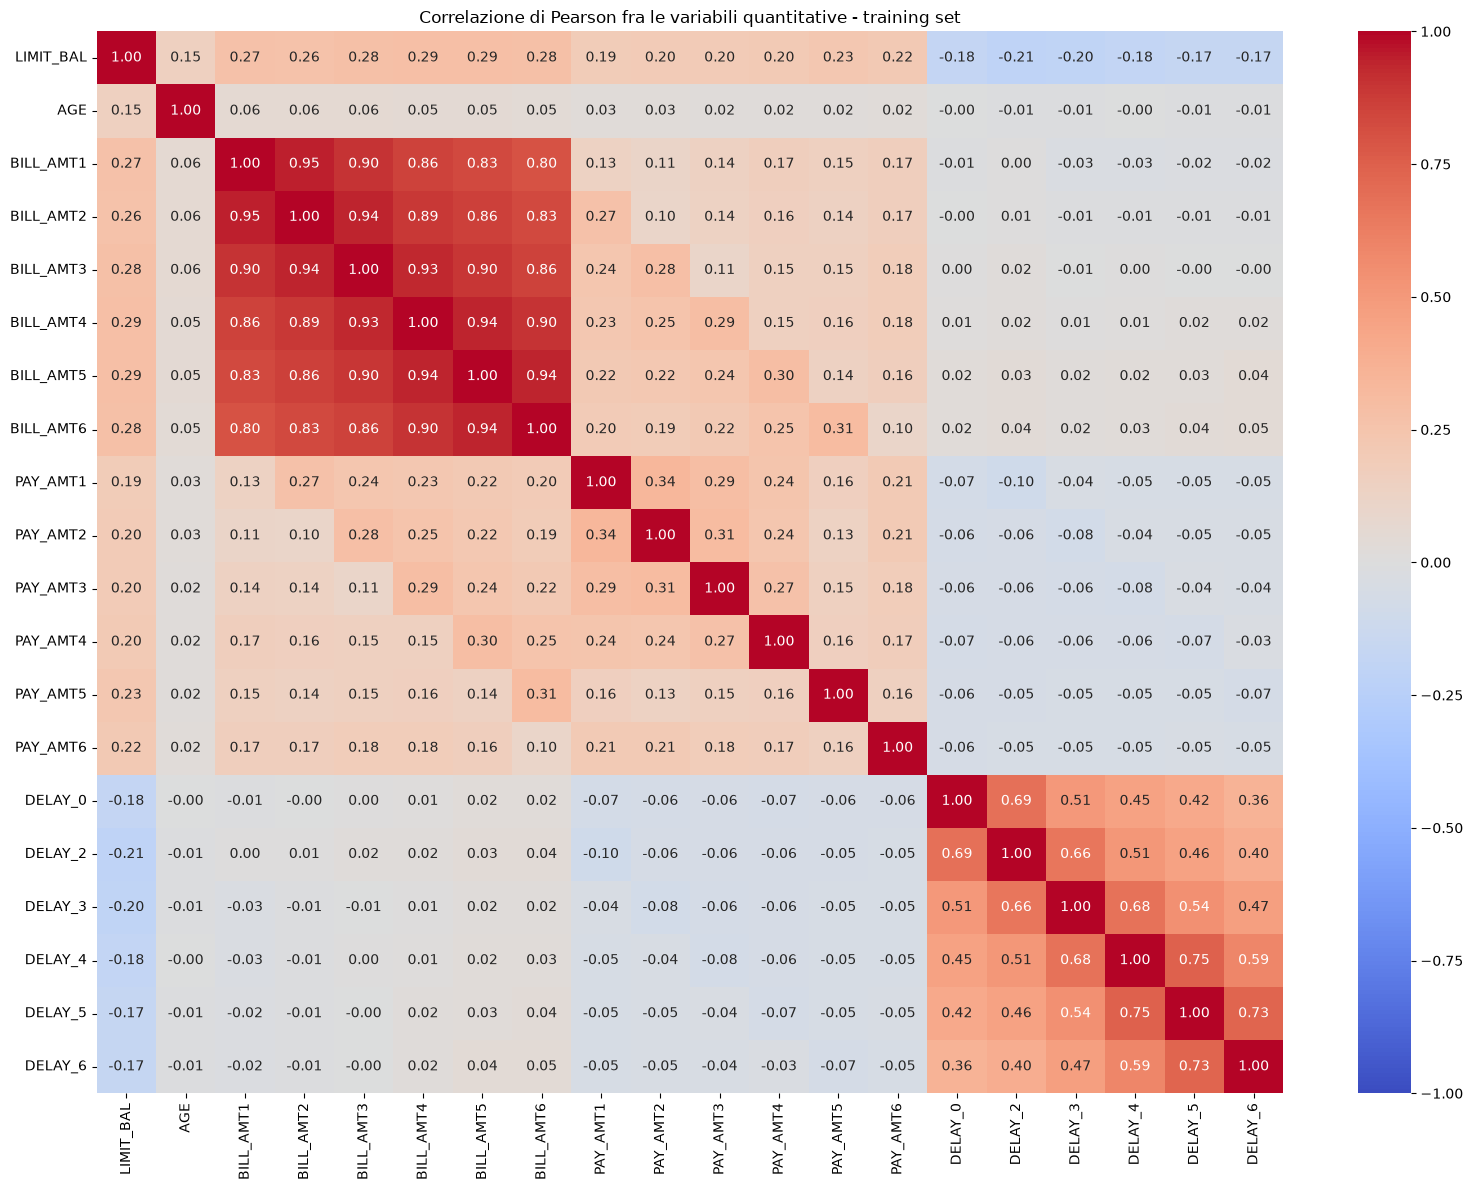

In [39]:
quantitativeColumns = ["LIMIT_BAL", "AGE"] + billColumns + paymentColumns + delayColumns
corrMatrix = trainData[quantitativeColumns].corr()

plt.figure(figsize=(16, 12))
sns.heatmap(corrMatrix, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlazione di Pearson fra le variabili quantitative - training set")
plt.tight_layout()
plt.show()

In [40]:
correlationThreshold = 0.70

for i in range(len(quantitativeColumns)):
    for j in range(i + 1, len(quantitativeColumns)):
        if abs(corrMatrix.iloc[i, j]) >= correlationThreshold:
            print(quantitativeColumns[i], "-", quantitativeColumns[j], round(corrMatrix.iloc[i, j], 3))

BILL_AMT1 - BILL_AMT2 0.951
BILL_AMT1 - BILL_AMT3 0.901
BILL_AMT1 - BILL_AMT4 0.858
BILL_AMT1 - BILL_AMT5 0.831
BILL_AMT1 - BILL_AMT6 0.799
BILL_AMT2 - BILL_AMT3 0.939
BILL_AMT2 - BILL_AMT4 0.89
BILL_AMT2 - BILL_AMT5 0.862
BILL_AMT2 - BILL_AMT6 0.83
BILL_AMT3 - BILL_AMT4 0.933
BILL_AMT3 - BILL_AMT5 0.895
BILL_AMT3 - BILL_AMT6 0.857
BILL_AMT4 - BILL_AMT5 0.941
BILL_AMT4 - BILL_AMT6 0.899
BILL_AMT5 - BILL_AMT6 0.943
DELAY_4 - DELAY_5 0.746
DELAY_5 - DELAY_6 0.733


Le coppie sopra soglia sono 17, tutte positive. Le sei `BILL_AMT` sono lo stesso saldo in mesi consecutivi (da 0,951 per `BILL_AMT1`-`BILL_AMT2` a 0,799 per `BILL_AMT1`-`BILL_AMT6`); `DELAY_5` è legata a `DELAY_4` (0,746) e a `DELAY_6` (0,733).

Regola: le coppie si esaminano dalla correlazione più alta alla più bassa e, se entrambe le variabili sono ancora presenti, si elimina quella del mese più vecchio, perché quella recente è più vicina al mese da prevedere. Delle `BILL_AMT` resta così solo `BILL_AMT1`; `DELAY_5` esce nella coppia con `DELAY_4`, e così scompare anche la coppia `DELAY_5`-`DELAY_6`. Restano 14 variabili quantitative e 6 indicatori: 20 feature in tutto.

In [41]:
featuresToRemove = ["BILL_AMT2", "BILL_AMT3", "BILL_AMT4", "BILL_AMT5", "BILL_AMT6", "DELAY_5"]
quantitativeColumns = [column for column in quantitativeColumns if column not in featuresToRemove]
inputColumns = quantitativeColumns + binaryColumns

remainingCorrelation = trainData[quantitativeColumns].corr().abs() - np.eye(len(quantitativeColumns))
print("Feature:", len(inputColumns))
print("Correlazione assoluta massima rimasta:", round(remainingCorrelation.max().max(), 3))

Feature: 20
Correlazione assoluta massima rimasta: 0.687


Dopo la rimozione la correlazione assoluta massima fra le variabili rimaste è 0,687.

**Normalizzazione.** Gli importi pagati `PAY_AMT` sono non negativi e molto asimmetrici (pochi pagamenti enormi, molti zeri): si applica $\log(1+x)$, definito anche per $x = 0$. Poi tutte le variabili quantitative passano allo z-score $(x - \mu)/\sigma$, con media e deviazione standard del solo training set, riusate per validation e test. Gli indicatori 0/1 restano invariati.

In [42]:
trainInput = trainData[inputColumns].astype(float)
validationInput = validationData[inputColumns].astype(float)
testInput = testData[inputColumns].astype(float)

for inputData in [trainInput, validationInput, testInput]:
    inputData[paymentColumns] = np.log1p(inputData[paymentColumns])     # importi pagati: logaritmo

trainMean = trainInput[quantitativeColumns].mean()                      # statistiche del solo training set
trainStd = trainInput[quantitativeColumns].std()
for inputData in [trainInput, validationInput, testInput]:
    inputData[quantitativeColumns] = (inputData[quantitativeColumns] - trainMean) / trainStd

trainX, validationX, testX = trainInput.to_numpy(), validationInput.to_numpy(), testInput.to_numpy()
trainY = trainData[targetColumn].to_numpy()
validationY = validationData[targetColumn].to_numpy()
testY = testData[targetColumn].to_numpy()
inputs = {"Training": trainX, "Validation": validationX, "Test": testX}
targets = {"Training": trainY, "Validation": validationY, "Test": testY}

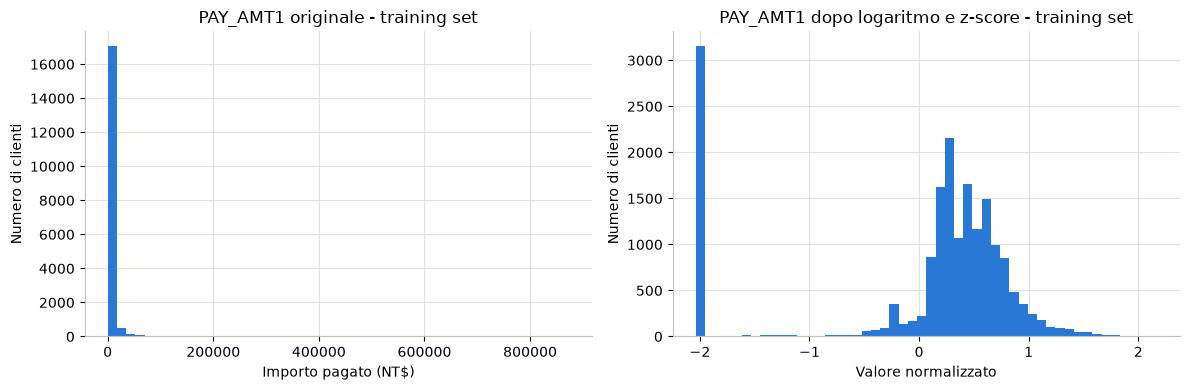

In [43]:
figure, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(trainData["PAY_AMT1"], bins=50)
axes[0].set_title("PAY_AMT1 originale - training set")
axes[0].set_xlabel("Importo pagato (NT$)")
axes[1].hist(trainInput["PAY_AMT1"], bins=50)
axes[1].set_title("PAY_AMT1 dopo logaritmo e z-score - training set")
axes[1].set_xlabel("Valore normalizzato")
for axis in axes:
    axis.set_ylabel("Numero di clienti")
    axis.grid(True)
plt.tight_layout()
plt.show()

## 5. Modelli e confronto sul validation set

Ogni modello stima la probabilità di default $\hat p(x)$; un cliente è classificato in default se $\hat p(x) \geq t$, con soglia $t$ (0,50 finché la soglia non viene scelta nella sezione 6). Le misure sono la cross-entropy (loss, più bassa è meglio), l'accuracy e la ROC-AUC.

La **baseline** assegna a tutti la stessa probabilità, la frequenza di default del training set: con soglia 0,50 prevede "nessun default" per tutti, cioè la classe più frequente.

Iperparametri, modello finale e soglie si scelgono solo sul validation set. A scopo di studio, nella sezione 8 tutti e cinque i modelli vengono valutati anche sul test set, per confrontarli su training, validation e test. In un'applicazione reale il test set si userebbe una sola volta, per il solo modello scelto sul validation set; il confronto sul test non viene usato per alcuna scelta.

In [44]:
def binaryCrossEntropy(target, probability):
    """Cross-entropy media; il clip evita log(0)."""
    probability = np.clip(probability, 1e-7, 1 - 1e-7)
    return -np.mean(target * np.log(probability) + (1 - target) * np.log(1 - probability))


def classificationMetrics(target, probability, threshold):
    """Metriche di classificazione con il default come classe positiva."""
    prediction = probability >= threshold
    truePositive = np.sum(prediction & (target == 1))
    falsePositive = np.sum(prediction & (target == 0))
    falseNegative = np.sum(~prediction & (target == 1))
    trueNegative = np.sum(~prediction & (target == 0))
    predictedDefaults = truePositive + falsePositive     # se è 0, la precision viene posta a 0
    return {"Soglia": threshold,
            "Accuracy": (truePositive + trueNegative) / len(target),
            "Precision": truePositive / predictedDefaults if predictedDefaults > 0 else 0.0,
            "Recall": truePositive / (truePositive + falseNegative),
            "Falsi positivi": falsePositive,
            "Falsi negativi": falseNegative}


def lossAndAccuracy(trainProbability, validationProbability):
    """Loss e accuracy (soglia 0.50) su training e validation set."""
    return {"Training loss": binaryCrossEntropy(trainY, trainProbability),
            "Validation loss": binaryCrossEntropy(validationY, validationProbability),
            "Training accuracy": np.mean((trainProbability >= 0.5) == trainY),
            "Validation accuracy": np.mean((validationProbability >= 0.5) == validationY)}


baselineProbability = trainY.mean()     # la baseline assegna a tutti la frequenza di default del training set
models = {}                             # modelli finali, uno per famiglia

baselineValidation = np.full(len(validationY), baselineProbability)
baselineLoss = binaryCrossEntropy(validationY, baselineValidation)
baselineAccuracy = classificationMetrics(validationY, baselineValidation, 0.50)["Accuracy"]
print("Baseline - cross-entropy sul validation set:", round(baselineLoss, 4))
print("Baseline - accuracy sul validation set:", round(baselineAccuracy, 4))

Baseline - cross-entropy sul validation set: 0.5284
Baseline - accuracy sul validation set: 0.7788


### Regressione logistica e reti neurali (Keras)

La regressione logistica è $\hat p(x) = 1/(1 + e^{-z})$ con $z = \theta_0 + \sum_j \theta_j x_j$: una rete senza strati interni. Le reti aggiungono strati interni con ReLU, $\max(0, z)$:

- **piccola**: 16 neuroni;
- **media**: 32 e 16 neuroni;
- **grande**: 64 e 32 neuroni, con dropout 0,3 (durante l'addestramento il 30% dei neuroni di ogni strato interno viene spento a caso, per limitare l'overfitting).

Tutti usano Adam, la loss `binary_crossentropy`, mini-batch da 32 e al massimo 200 epoche. L'early stopping ferma l'addestramento dopo 10 epoche senza miglioramento della validation loss e ripristina i pesi dell'epoca migliore. I semi fissi rendono i risultati riproducibili.

In [45]:
random.seed(randomSeed)
np.random.seed(randomSeed)
tf.random.set_seed(randomSeed)
tf.config.experimental.enable_op_determinism()

numberOfFeatures = trainX.shape[1]
kerasModels = {
    "Regressione logistica": Sequential([
        InputLayer(shape=(numberOfFeatures,)),
        Dense(1, activation="sigmoid")]),
    "Rete piccola": Sequential([
        InputLayer(shape=(numberOfFeatures,)),
        Dense(16, activation="relu"),
        Dense(1, activation="sigmoid")]),
    "Rete media": Sequential([
        InputLayer(shape=(numberOfFeatures,)),
        Dense(32, activation="relu"),
        Dense(16, activation="relu"),
        Dense(1, activation="sigmoid")]),
    "Rete grande": Sequential([
        InputLayer(shape=(numberOfFeatures,)),
        Dense(64, activation="relu"),
        Dropout(0.3),
        Dense(32, activation="relu"),
        Dropout(0.3),
        Dense(1, activation="sigmoid")]),
}

histories = {}
for modelName, model in kerasModels.items():
    model.compile(optimizer="adam", loss="binary_crossentropy")
    earlyStopping = EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True)
    history = model.fit(trainX, trainY, validation_data=(validationX, validationY),
                        epochs=200, batch_size=32, callbacks=[earlyStopping], verbose=0)
    histories[modelName] = history.history
    print(f"{modelName}: {model.count_params()} parametri, {len(history.history['loss'])} epoche eseguite, "
          f"epoca migliore {np.argmin(history.history['val_loss']) + 1}")

Regressione logistica: 21 parametri, 24 epoche eseguite, epoca migliore 14
Rete piccola: 353 parametri, 44 epoche eseguite, epoca migliore 34
Rete media: 1217 parametri, 25 epoche eseguite, epoca migliore 15
Rete grande: 3457 parametri, 36 epoche eseguite, epoca migliore 26


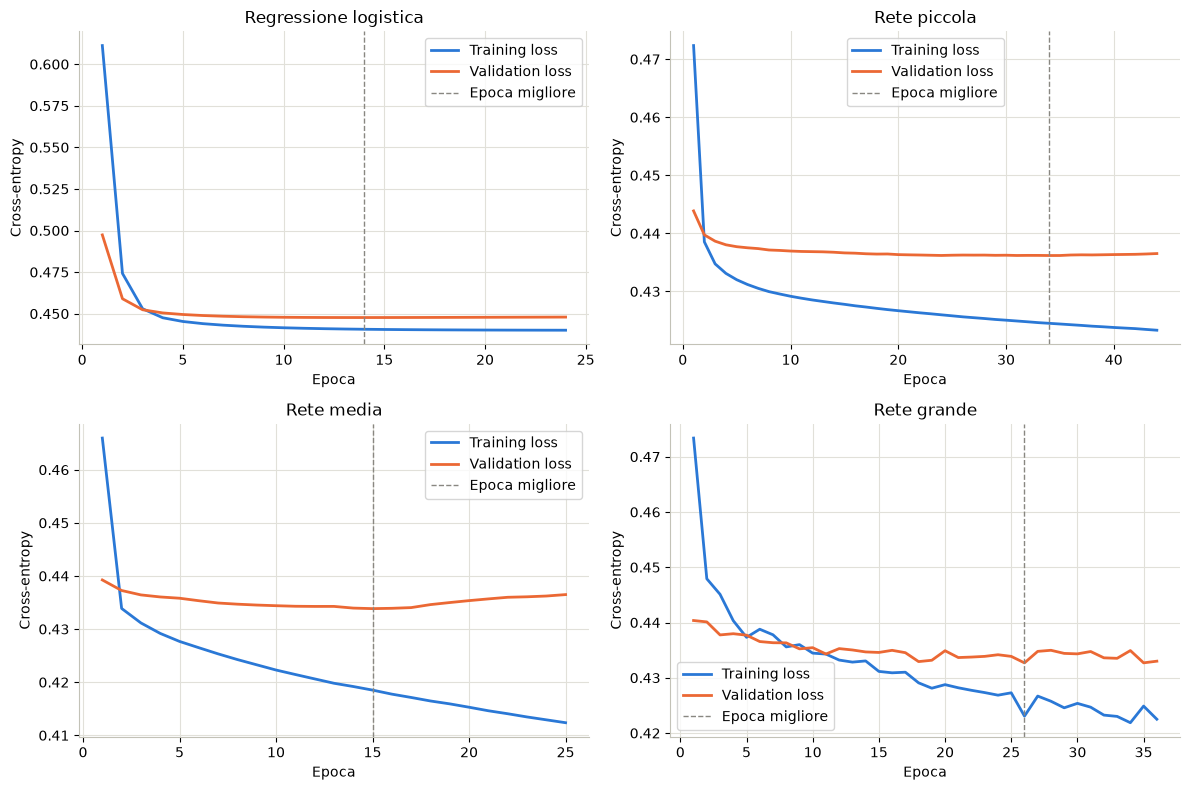

In [46]:
figure, axes = plt.subplots(2, 2, figsize=(12, 8))
for axis, modelName in zip(axes.flatten(), histories):
    history = histories[modelName]
    epochs = np.arange(1, len(history["loss"]) + 1)
    axis.plot(epochs, history["loss"], label="Training loss")
    axis.plot(epochs, history["val_loss"], label="Validation loss")
    bestEpoch = np.argmin(history["val_loss"]) + 1
    axis.axvline(bestEpoch, color="#898781", linestyle="--", linewidth=1, label="Epoca migliore")
    axis.set(title=modelName, xlabel="Epoca", ylabel="Cross-entropy")
    axis.grid(True)
    axis.legend()
plt.tight_layout()
plt.show()

La validation loss scende nelle prime epoche e poi si stabilizza. Nella regressione logistica le due curve restano vicine; nelle reti la training loss continua a scendere mentre la validation loss smette di migliorare: è l'inizio dell'overfitting, che l'early stopping interrompe. Nella rete grande la training loss è più irregolare perché viene calcolata con il dropout attivo.

In [47]:
kerasRows = {}
for modelName, model in kerasModels.items():
    trainProbability = model.predict(trainX, verbose=0).ravel()
    validationProbability = model.predict(validationX, verbose=0).ravel()
    kerasRows[modelName] = lossAndAccuracy(trainProbability, validationProbability)
kerasComparison = pd.DataFrame.from_dict(kerasRows, orient="index")
display(kerasComparison.round(4))

# Rete con la validation loss più bassa (la regressione logistica non partecipa al confronto fra reti)
networkName = kerasComparison["Validation loss"].drop("Regressione logistica").idxmin()
models["Regressione logistica"] = kerasModels["Regressione logistica"]
models["Rete neurale"] = kerasModels[networkName]
print("Rete scelta:", networkName)

,Training loss,Validation loss,Training accuracy,Validation accuracy
Regressione logistica,0.4400,0.4477,0.8195,0.8173
Rete piccola,0.4230,0.4362,0.8227,0.8190
Rete media,0.4159,0.4339,0.8264,0.8195
Rete grande,0.4148,0.4327,0.8277,0.8202


Rete scelta: Rete grande


La validation loss scende al crescere della rete: 0,4362 (piccola), 0,4339 (media), 0,4327 (grande). Si sceglie la rete grande. Il guadagno rispetto alla regressione logistica (0,4477) è contenuto.

### Random Forest

Ogni albero divide i clienti con domande successive su una feature alla volta; la probabilità di una foglia è la frequenza di default dei clienti di training che vi finiscono. La foresta fa la media di 500 alberi, ciascuno costruito su un campione casuale dei clienti e, a ogni divisione, su un sottoinsieme casuale di feature.

Si confronta il numero minimo di clienti per foglia (1, 5, 20, 50): foglie piccole danno alberi che imparano il training a memoria, foglie grandi probabilità più regolari.

In [48]:
forests = {}
forestRows = {}
for leafSize in [1, 5, 20, 50]:
    forest = RandomForestClassifier(n_estimators=500, min_samples_leaf=leafSize, n_jobs=-1,
                                    random_state=randomSeed)
    forest.fit(trainX, trainY)
    forests[leafSize] = forest
    trainProbability = forest.predict_proba(trainX)[:, 1]              # colonna 1: probabilità di default
    validationProbability = forest.predict_proba(validationX)[:, 1]
    forestRows[leafSize] = lossAndAccuracy(trainProbability, validationProbability)
forestComparison = pd.DataFrame.from_dict(forestRows, orient="index")
forestComparison.index.name = "Clienti minimi per foglia"
display(forestComparison.round(4))

selectedLeafSize = forestComparison["Validation loss"].idxmin()
models["Random Forest"] = forests[selectedLeafSize]
print("Clienti minimi per foglia scelti:", selectedLeafSize)

,Training loss,Validation loss,Training accuracy,Validation accuracy
Clienti minimi per foglia,,,,
1,0.1119,0.4339,0.9997,0.8180
5,0.2846,0.4265,0.8690,0.8208
20,0.3739,0.4259,0.8329,0.8218
50,0.4041,0.4286,0.8252,0.8200


Clienti minimi per foglia scelti: 20


Con foglie da un cliente la foresta impara il training quasi a memoria (training loss 0,1119, training accuracy 0,9997) e ha la validation loss peggiore (0,4339). La validation loss migliora fino a 20 clienti per foglia (0,4259) e risale con 50 (0,4286): si sceglie 20.

Sul training set la Random Forest appare molto migliore degli altri modelli perché ha già visto quei clienti: per confrontarla conta il validation set.

### Gradient Boosting

Gli alberi si aggiungono uno alla volta: ognuno corregge gli errori della somma dei precedenti, con un passo (learning rate) di 0,05. Il numero di alberi ha il ruolo delle epoche: si sceglie dove la validation loss è minima. Si confrontano anche 4, 8 e 16 foglie per albero.

Si usa `HistGradientBoostingClassifier` con `early_stopping=False`: altrimenti scikit-learn fermerebbe da solo l'addestramento usando un proprio campione di controllo.

In [49]:
boostingCurves = {}
boostingRows = {}
for leaves in [4, 8, 16]:
    boosting = HistGradientBoostingClassifier(learning_rate=0.05, max_iter=500, max_leaf_nodes=leaves,
                                              early_stopping=False, random_state=randomSeed)
    boosting.fit(trainX, trainY)
    curve = []
    for stageProbability in boosting.staged_predict_proba(validationX):     # probabilità dopo ogni albero
        curve.append(binaryCrossEntropy(validationY, stageProbability[:, 1]))
    boostingCurves[leaves] = curve
    boostingRows[leaves] = {"Alberi scelti": np.argmin(curve) + 1, "Validation loss minima": min(curve)}
boostingComparison = pd.DataFrame.from_dict(boostingRows, orient="index")
boostingComparison.index.name = "Foglie massime per albero"
display(boostingComparison.round(4))

selectedLeaves = boostingComparison["Validation loss minima"].idxmin()
selectedTrees = int(boostingComparison.loc[selectedLeaves, "Alberi scelti"])
# Riaddestramento con la configurazione scelta
selectedBoosting = HistGradientBoostingClassifier(learning_rate=0.05, max_iter=selectedTrees,
                                                  max_leaf_nodes=selectedLeaves, early_stopping=False,
                                                  random_state=randomSeed)
selectedBoosting.fit(trainX, trainY)
models["Gradient Boosting"] = selectedBoosting
print("Configurazione scelta:", selectedLeaves, "foglie per albero,", selectedTrees, "alberi")

,Alberi scelti,Validation loss minima
Foglie massime per albero,,
4,480,0.4307
8,112,0.4299
16,111,0.4291


Configurazione scelta: 16 foglie per albero, 111 alberi


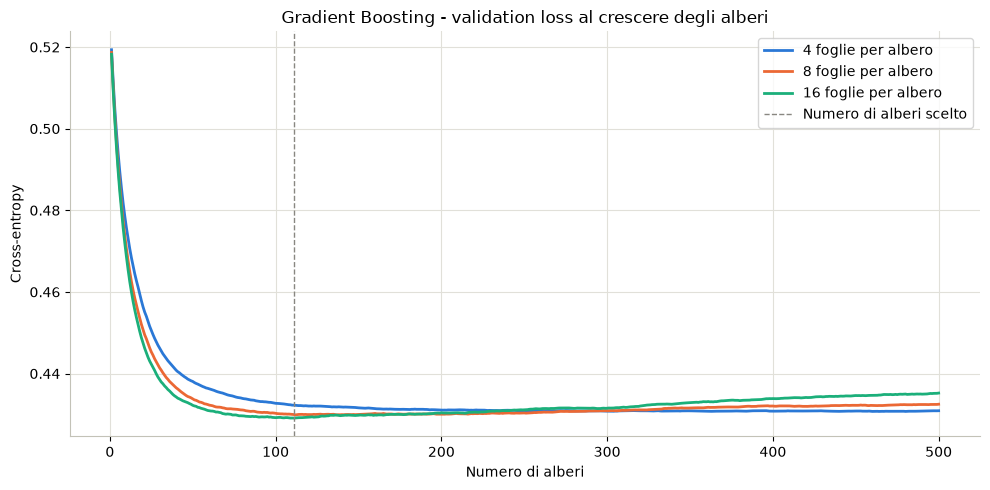

In [50]:
plt.figure(figsize=(10, 5))
for leaves in boostingCurves:
    plt.plot(np.arange(1, 501), boostingCurves[leaves], label=f"{leaves} foglie per albero")
plt.axvline(selectedTrees, color="#898781", linestyle="--", linewidth=1, label="Numero di alberi scelto")
plt.title("Gradient Boosting - validation loss al crescere degli alberi")
plt.xlabel("Numero di alberi")
plt.ylabel("Cross-entropy")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

Le tre validation loss minime sono molto vicine: 0,4307 (4 foglie, 480 alberi), 0,4299 (8 foglie, 112 alberi), 0,4291 (16 foglie, 111 alberi). Con 8 e 16 foglie, dopo il minimo la loss risale lentamente: è l'overfitting che la scelta del numero di alberi evita. Si sceglie 16 foglie e 111 alberi.

### Confronto e scelta del modello finale

L'ensemble fa la media delle probabilità dei quattro modelli. La ROC-AUC è la probabilità che un cliente in default scelto a caso riceva un rischio stimato più alto di un cliente senza default scelto a caso: 0,5 per un ordinamento casuale, 1 per uno perfetto; non dipende dalla soglia.

Regola fissata prima del confronto: il modello finale è quello con la validation loss più bassa.

In [51]:
def predictProbability(modelName, inputMatrix):
    """Probabilità di default stimate da un modello."""
    if modelName == "Baseline":
        return np.full(len(inputMatrix), baselineProbability)
    if modelName == "Ensemble":
        return np.mean([predictProbability(name, inputMatrix) for name in models], axis=0)
    model = models[modelName]
    if hasattr(model, "predict_proba"):                      # scikit-learn
        return model.predict_proba(inputMatrix)[:, 1]
    return model.predict(inputMatrix, verbose=0).ravel()     # Keras


modelNames = list(models) + ["Ensemble"]
rowNames = ["Baseline"] + modelNames
probability = {}        # chiave: (nome, insieme)
validationRows = {}
for rowName in rowNames:
    for setName in ["Training", "Validation"]:
        probability[rowName, setName] = predictProbability(rowName, inputs[setName])
    validationRows[rowName] = lossAndAccuracy(probability[rowName, "Training"], probability[rowName, "Validation"])
    validationRows[rowName]["Validation ROC-AUC"] = roc_auc_score(validationY, probability[rowName, "Validation"])
validationComparison = pd.DataFrame.from_dict(validationRows, orient="index")
display(validationComparison.round(4))

selectedModelName = validationComparison.loc[modelNames, "Validation loss"].idxmin()
print("Modello finale:", selectedModelName)

,Training loss,Validation loss,Training accuracy,Validation accuracy,Validation ROC-AUC
Baseline,0.5285,0.5284,0.7788,0.7788,0.5000
Regressione logistica,0.4400,0.4477,0.8195,0.8173,0.7669
Rete neurale,0.4148,0.4327,0.8277,0.8202,0.7786
Random Forest,0.3739,0.4259,0.8329,0.8218,0.7861
Gradient Boosting,0.4015,0.4291,0.8296,0.8213,0.7802
Ensemble,0.4025,0.4280,0.8279,0.8212,0.7842


Modello finale: Random Forest


Tutti i modelli battono la baseline: validation loss fra 0,4259 e 0,4477 contro 0,5284, accuracy fra 0,8173 e 0,8218 contro 0,7788. La Random Forest ha la validation loss più bassa (0,4259) e anche la ROC-AUC più alta (0,7861): è il modello finale. Seguono l'ensemble (0,4280) e il Gradient Boosting (0,4291); la regressione logistica è indietro su tutte le misure. Le differenze fra i modelli non lineari sono di pochi millesimi.

## 6. Soglia di classificazione

Con il default come classe positiva: precision = VP / (VP + FP), la quota di veri default fra i clienti segnalati; recall = VP / (VP + FN), la quota di default individuati. Un falso negativo (default non previsto) è l'errore più costoso nel credito, perché il prestito non viene restituito; un falso positivo costa un cliente buono rifiutato o controllato.

Per ogni modello si scelgono sul validation set, fra le soglie da 0,05 a 0,95 con passo 0,01, due soglie:

- **soglia di massima accuracy**: l'accuracy più alta (a parità, la soglia più bassa);
- **soglia prudente**: fra le soglie con accuracy al massimo 2 punti sotto la migliore e precision almeno 0,50 (almeno un cliente segnalato su due è un vero default), quella con meno falsi negativi (a parità, la più alta).

I due vincoli sono una scelta di progetto; la tabella di sensibilità più sotto mostra cosa cambia variandoli.

In [52]:
thresholdValues = np.arange(5, 96) / 100     # soglie da 0.05 a 0.95, passo 0.01
maximumAccuracyLoss = 0.02      # accuracy: al massimo 2 punti sotto la migliore
minimumPrecision = 0.50         # almeno un cliente segnalato su due è un vero default


def chooseThresholds(target, probability, accuracyLoss):
    """Soglia di massima accuracy e soglia prudente."""
    metrics = pd.DataFrame([classificationMetrics(target, probability, threshold)
                            for threshold in thresholdValues])
    bestAccuracy = metrics["Accuracy"].max()
    accuracyThreshold = metrics.loc[metrics["Accuracy"].idxmax(), "Soglia"]     # a parità, la più bassa
    admissible = metrics[(metrics["Accuracy"] >= bestAccuracy - accuracyLoss - 1e-9)   # 1e-9: tolleranza numerica
                         & (metrics["Precision"] >= minimumPrecision)]
    fewest = admissible[admissible["Falsi negativi"] == admissible["Falsi negativi"].min()]
    return accuracyThreshold, fewest["Soglia"].max()                             # a parità, la più alta


accuracyThresholds = {"Baseline": 0.50}     # la baseline non ha soglie da scegliere: resta 0.50
prudentThresholds = {"Baseline": 0.50}
for modelName in modelNames:
    accuracyThresholds[modelName], prudentThresholds[modelName] = chooseThresholds(
        validationY, probability[modelName, "Validation"], maximumAccuracyLoss)
display(pd.DataFrame({"Soglia di massima accuracy": accuracyThresholds, "Soglia prudente": prudentThresholds}))

,Soglia di massima accuracy,Soglia prudente
Baseline,0.50,0.50
Regressione logistica,0.42,0.30
Rete neurale,0.50,0.31
Random Forest,0.49,0.31
Gradient Boosting,0.46,0.32
Ensemble,0.45,0.32


Le soglie di massima accuracy restano vicine a 0,50 (da 0,42 a 0,50). Le soglie prudenti sono più basse, da 0,30 a 0,32 per tutti i modelli: un cliente viene segnalato già con un rischio stimato intorno al 30%.

In [53]:
finalValidationProbability = probability[selectedModelName, "Validation"]
finalThresholds = {"Soglia 0.50": 0.50,
                   "Soglia di massima accuracy": accuracyThresholds[selectedModelName],
                   "Soglia prudente": prudentThresholds[selectedModelName]}

finalRows = {}
for rowName, threshold in finalThresholds.items():
    finalRows[rowName] = classificationMetrics(validationY, finalValidationProbability, threshold)
display(pd.DataFrame.from_dict(finalRows, orient="index").round(4))

prudentThreshold = prudentThresholds[selectedModelName]
print(f"Rapporto di costo implicito della soglia prudente: {(1 - prudentThreshold) / prudentThreshold:.2f}")

,Soglia,Accuracy,Precision,Recall,Falsi positivi,Falsi negativi
Soglia 0.50,0.50,0.8218,0.6891,0.3542,212,857
Soglia di massima accuracy,0.49,0.8227,0.6865,0.3647,221,843
Soglia prudente,0.31,0.8047,0.5610,0.5373,558,614


Rapporto di costo implicito della soglia prudente: 2.23


Per la Random Forest la soglia di massima accuracy (0,49) cambia poco rispetto a 0,50: accuracy 0,8227 contro 0,8218. La soglia prudente 0,31 riduce i falsi negativi da 843 a 614 e porta il recall da 0,3647 a 0,5373; in cambio i falsi positivi salgono da 221 a 558, la precision scende a 0,5610 e l'accuracy a 0,8047, sempre sopra la baseline (0,7788).

Se le probabilità sono affidabili, una soglia $t$ è quella giusta quando un falso negativo costa $(1 - t)/t$ volte un falso positivo: per $t = 0{,}31$ il rapporto è 2,23. Nel credito un default non previsto costa in genere più di un cliente buono segnalato per errore, per questo la soglia operativa è quella prudente.

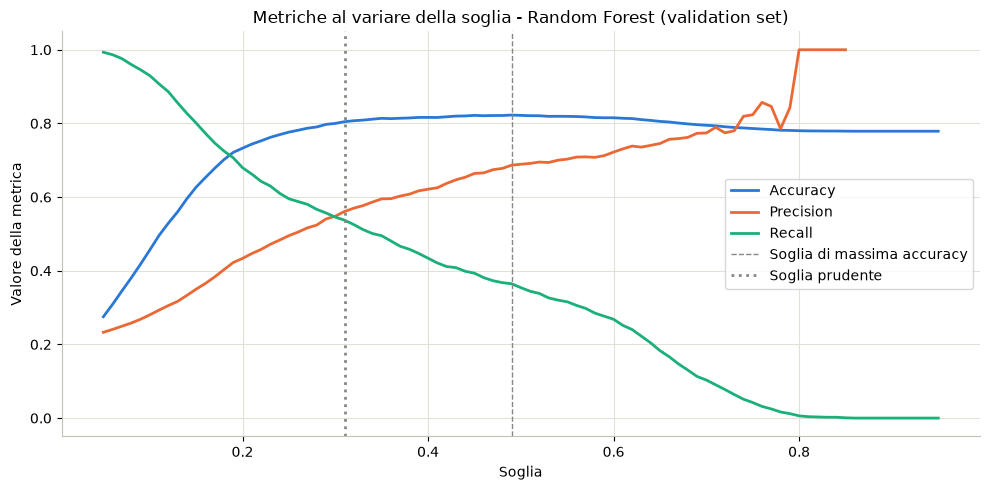

In [54]:
finalMetrics = pd.DataFrame([classificationMetrics(validationY, finalValidationProbability, threshold)
                             for threshold in thresholdValues])
# La precision non si disegna oltre la probabilità massima, dove non viene previsto alcun default
precisionCurve = finalMetrics["Precision"].where(thresholdValues <= finalValidationProbability.max())

plt.figure(figsize=(10, 5))
plt.plot(thresholdValues, finalMetrics["Accuracy"], label="Accuracy")
plt.plot(thresholdValues, precisionCurve, label="Precision")
plt.plot(thresholdValues, finalMetrics["Recall"], label="Recall")
plt.axvline(finalThresholds["Soglia di massima accuracy"], color="#898781", linestyle="--", linewidth=1,
            label="Soglia di massima accuracy")
plt.axvline(prudentThreshold, color="#898781", linestyle=":", linewidth=2, label="Soglia prudente")
plt.title("Metriche al variare della soglia - " + selectedModelName + " (validation set)")
plt.xlabel("Soglia")
plt.ylabel("Valore della metrica")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

**Sensibilità.** La tabella ripete la scelta della soglia prudente del modello finale ammettendo da 0 a 4 punti di accuracy in meno rispetto alla migliore (vincolo sulla precision invariato).

In [55]:
sensitivityRows = {}
for accuracyLoss in [0.00, 0.01, 0.02, 0.03, 0.04]:
    # chooseThresholds restituisce due soglie: [1] è la soglia prudente
    threshold = chooseThresholds(validationY, finalValidationProbability, accuracyLoss)[1]
    sensitivityRows[accuracyLoss] = classificationMetrics(validationY, finalValidationProbability, threshold)
sensitivity = pd.DataFrame.from_dict(sensitivityRows, orient="index")
sensitivity.index.name = "Perdita di accuracy ammessa"
display(sensitivity.round(4))

,Soglia,Accuracy,Precision,Recall,Falsi positivi,Falsi negativi
Perdita di accuracy ammessa,,,,,,
0.00,0.49,0.8227,0.6865,0.3647,221,843
0.01,0.35,0.8138,0.5951,0.4951,447,670
0.02,0.31,0.8047,0.5610,0.5373,558,614
0.03,0.29,0.7973,0.5406,0.5569,628,588
0.04,0.27,0.7870,0.5164,0.5803,721,557


Senza perdita di accuracy la soglia prudente coincide con quella di massima accuracy (0,49). Concedendo 1 punto scende a 0,35 (670 falsi negativi), con 2 punti a 0,31 (614), con 4 punti a 0,27 (557): il primo punto vale molto, i successivi sempre meno. Anche con 4 punti la precision resta sopra 0,50 (0,5164): per la Random Forest il vincolo che decide è quello sull'accuracy.

## 7. Lettura del modello finale

Due letture, entrambe sul validation set.

- **Pesi della regressione logistica.** A parità delle altre feature, un peso positivo aumenta il rischio stimato. Le feature quantitative sono standardizzate, quindi i loro pesi sono confrontabili; per un indicatore 0/1 il peso si legge rispetto alla categoria di riferimento.
- **Importanza per permutazione del modello finale.** Si rimescolano i valori di una feature fra i clienti e si misura quanto sale la validation loss (media di 5 rimescolamenti): più sale, più il modello dipende da quella feature.

In [56]:
weights, bias = models["Regressione logistica"].get_weights()
logisticWeights = pd.Series(weights.ravel(), index=inputColumns, name="Peso")
display(logisticWeights.sort_values(key=np.abs, ascending=False).round(4).to_frame())

,Peso
EDUCATION_OTHER,-1.0700
DELAY_0,0.6760
LIMIT_BAL,-0.3050
MARRIAGE_SINGLE,-0.2627
EDUCATION_HIGH_SCHOOL,-0.1993
SEX_FEMALE,-0.1727
BILL_AMT1,0.1530
MARRIAGE_OTHER,-0.1498
DELAY_6,0.1394
EDUCATION_UNIVERSITY,-0.0939


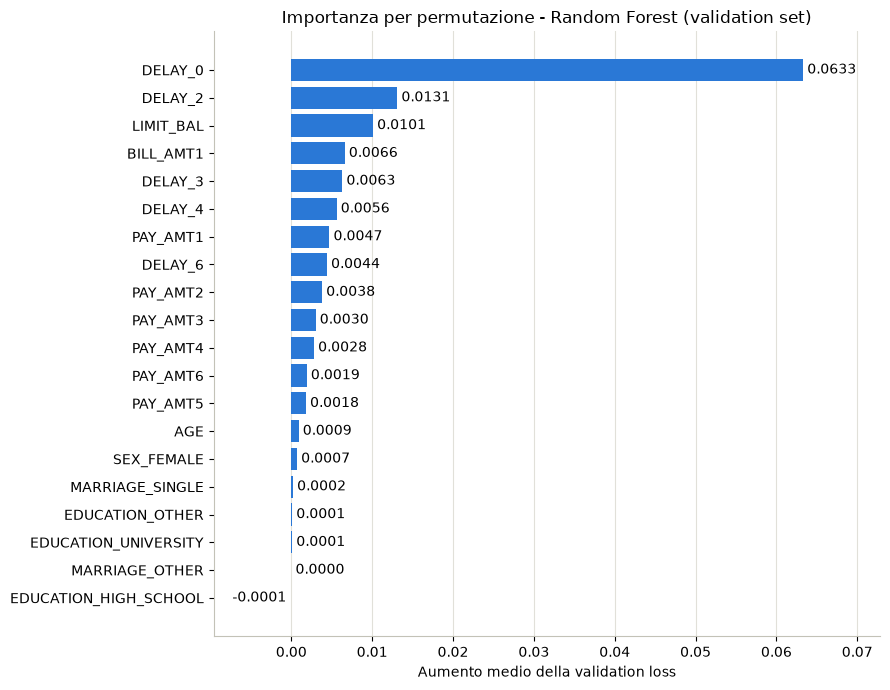

In [57]:
generator = np.random.default_rng(randomSeed)
referenceLoss = binaryCrossEntropy(validationY, finalValidationProbability)

importance = {}
for featureIndex, featureName in enumerate(inputColumns):
    increases = []
    for repeat in range(5):
        permutedX = validationX.copy()
        permutedX[:, featureIndex] = generator.permutation(permutedX[:, featureIndex])
        permutedLoss = binaryCrossEntropy(validationY, predictProbability(selectedModelName, permutedX))
        increases.append(permutedLoss - referenceLoss)
    importance[featureName] = np.mean(increases)
importance = pd.Series(importance).round(4).sort_values() + 0.0     # + 0.0: un eventuale -0.0000 diventa 0.0000

plt.figure(figsize=(9, 7))
bars = plt.barh(importance.index, importance.values)
plt.bar_label(bars, fmt="%.4f", padding=3)
plt.title("Importanza per permutazione - " + selectedModelName + " (validation set)")
plt.xlabel("Aumento medio della validation loss")
plt.margins(x=0.15)
plt.grid(True, axis="x")
plt.tight_layout()
plt.show()

Per la Random Forest la feature di gran lunga più importante è `DELAY_0`, i mesi di ritardo di settembre: rimescolarla alza la validation loss di 0,0633, contro 0,0131 di `DELAY_2`, 0,0101 di `LIMIT_BAL` e 0,0066 di `BILL_AMT1`. Sesso, istruzione e stato civile contano pochissimo (al più 0,0007); valori vicini a zero o leggermente negativi sono dovuti al caso del rimescolamento.

Nella regressione logistica `DELAY_0` ha il peso più grande fra le feature quantitative (0,6760: più ritardo, più rischio) e `LIMIT_BAL` un peso negativo (-0,3050: a parità del resto, un credito concesso più alto si associa a un rischio minore). `EDUCATION_OTHER` ha il peso più grande in valore assoluto (-1,0700), ma riguarda una categoria rara e per la Random Forest è quasi irrilevante (0,0001).

## 8. Verifica sul test set

Tutte le scelte sono fissate. A scopo di studio si valutano sul test set tutti e cinque i modelli; la stima delle prestazioni è quella del modello finale.

La prima tabella confronta loss e ROC-AUC sui tre insiemi; la seconda l'accuracy alla soglia di massima accuracy di ciascun modello; le tre successive tutte le metriche alla soglia prudente.

In [58]:
for rowName in rowNames:
    probability[rowName, "Test"] = predictProbability(rowName, testX)
setNames = ["Training", "Validation", "Test"]

probabilityComparison = pd.DataFrame(index=rowNames)
for setName in setNames:
    probabilityComparison["Loss " + setName] = [binaryCrossEntropy(targets[setName], probability[rowName, setName])
                                                for rowName in rowNames]
for setName in setNames:
    probabilityComparison["ROC-AUC " + setName] = [roc_auc_score(targets[setName], probability[rowName, setName])
                                                   for rowName in rowNames]
display(probabilityComparison.round(4))

,Loss Training,Loss Validation,Loss Test,ROC-AUC Training,ROC-AUC Validation,ROC-AUC Test
Baseline,0.5285,0.5284,0.5284,0.5000,0.5000,0.5000
Regressione logistica,0.4400,0.4477,0.4470,0.7700,0.7669,0.7545
Rete neurale,0.4148,0.4327,0.4339,0.8019,0.7786,0.7757
Random Forest,0.3739,0.4259,0.4321,0.8773,0.7861,0.7738
Gradient Boosting,0.4015,0.4291,0.4309,0.8214,0.7802,0.7780
Ensemble,0.4025,0.4280,0.4314,0.8304,0.7842,0.7771


Sul training set la Random Forest ha la loss più bassa (0,3739) e la ROC-AUC più alta (0,8773) perché ha già visto quei clienti; il confronto che conta è fra validation e test. Passando al test la sua loss sale da 0,4259 a 0,4321, più che negli altri modelli, e il Gradient Boosting risulta primo sia in loss (0,4309) sia in ROC-AUC (0,7780). Le differenze fra i quattro modelli non lineari restano di pochi millesimi; la baseline ha 0,5284 anche sul test.

In [59]:
def classificationTable(setName, thresholds):
    """Metriche di tutte le righe su un insieme, ciascuna con la propria soglia."""
    rows = {}
    for rowName in rowNames:
        rows[rowName] = classificationMetrics(targets[setName], probability[rowName, setName], thresholds[rowName])
    table = pd.DataFrame.from_dict(rows, orient="index")
    advantage = (table["Accuracy"] - table.loc["Baseline", "Accuracy"]) * 100
    table["Vantaggio sulla baseline (punti %)"] = advantage.round(2)
    return table


accuracyComparison = pd.DataFrame({"Soglia": accuracyThresholds})
for setName in setNames:
    accuracyComparison["Accuracy " + setName] = classificationTable(setName, accuracyThresholds)["Accuracy"]
testTable = classificationTable("Test", accuracyThresholds)
accuracyComparison["Vantaggio sul test (punti %)"] = testTable["Vantaggio sulla baseline (punti %)"]
display(accuracyComparison.round(4))

,Soglia,Accuracy Training,Accuracy Validation,Accuracy Test,Vantaggio sul test (punti %)
Baseline,0.50,0.7788,0.7788,0.7788,0.00
Regressione logistica,0.42,0.8174,0.8185,0.8148,3.60
Rete neurale,0.50,0.8277,0.8202,0.8167,3.78
Random Forest,0.49,0.8329,0.8227,0.8170,3.82
Gradient Boosting,0.46,0.8306,0.8223,0.8182,3.93
Ensemble,0.45,0.8288,0.8232,0.8173,3.85


Alla soglia di massima accuracy tutti i modelli superano la baseline (0,7788) anche sul test: il vantaggio va da 3,60 punti percentuali (regressione logistica, 0,8148) a 3,93 (Gradient Boosting, 0,8182). La Random Forest ha 0,8170 sul test contro 0,8227 sul validation.

In [60]:
for setName in setNames:
    print(setName, "- soglia prudente")
    display(classificationTable(setName, prudentThresholds).round(4))

Training - soglia prudente


,Soglia,Accuracy,Precision,Recall,Falsi positivi,Falsi negativi,Vantaggio sulla baseline (punti %)
Baseline,0.50,0.7788,0.0000,0.0000,0,3982,0.00
Regressione logistica,0.30,0.7989,0.5483,0.5178,1699,1920,2.02
Rete neurale,0.31,0.8088,0.5705,0.5485,1644,1798,3.00
Random Forest,0.31,0.8214,0.5975,0.5904,1584,1631,4.26
Gradient Boosting,0.32,0.8178,0.5960,0.5480,1479,1800,3.91
Ensemble,0.32,0.8157,0.5904,0.5445,1504,1814,3.69


Validation - soglia prudente


,Soglia,Accuracy,Precision,Recall,Falsi positivi,Falsi negativi,Vantaggio sulla baseline (punti %)
Baseline,0.50,0.7788,0.0000,0.0000,0,1327,0.00
Regressione logistica,0.30,0.7993,0.5513,0.4981,538,666,2.05
Rete neurale,0.31,0.8002,0.5506,0.5252,569,630,2.13
Random Forest,0.31,0.8047,0.5610,0.5373,558,614,2.58
Gradient Boosting,0.32,0.8055,0.5667,0.5124,520,647,2.67
Ensemble,0.32,0.8060,0.5679,0.5139,519,645,2.72


Test - soglia prudente


,Soglia,Accuracy,Precision,Recall,Falsi positivi,Falsi negativi,Vantaggio sulla baseline (punti %)
Baseline,0.50,0.7788,0.0000,0.0000,0,1327,0.00
Regressione logistica,0.30,0.7960,0.5421,0.4996,560,664,1.72
Rete neurale,0.31,0.7988,0.5478,0.5177,567,640,2.00
Random Forest,0.31,0.8003,0.5500,0.5343,580,618,2.15
Gradient Boosting,0.32,0.8013,0.5556,0.5079,539,653,2.25
Ensemble,0.32,0.8013,0.5560,0.5049,535,657,2.25


Alla soglia prudente le metriche passano dal validation al test quasi invariate: per la Random Forest recall 0,5373 e 0,5343, precision 0,5610 e 0,5500. Il vincolo di precision regge sul test per tutti i modelli (da 0,5421 a 0,5560). Sul test la Random Forest ha meno falsi negativi di tutti (618); Gradient Boosting ed ensemble hanno un'accuracy appena più alta (0,8013 contro 0,8003) ma più falsi negativi (653 e 657). Sul training la Random Forest appare migliore (recall 0,5904) perché conosce già quei clienti.

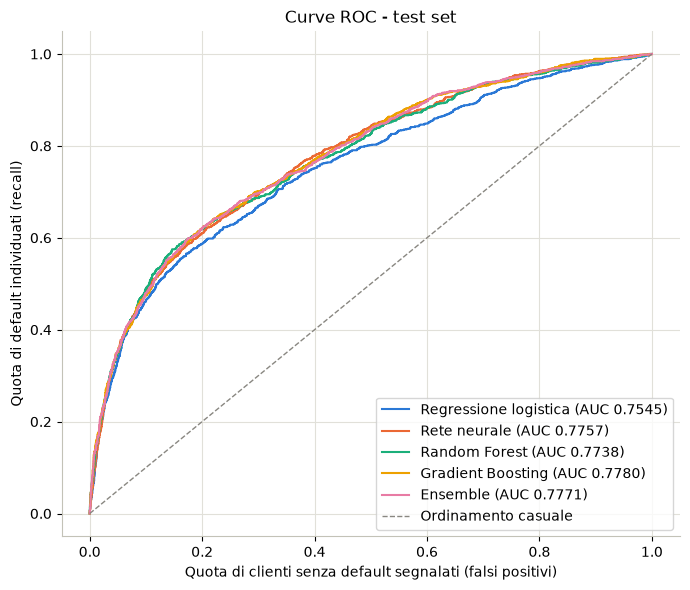

In [61]:
plt.figure(figsize=(7, 6))
for modelName in modelNames:
    falsePositiveRate, truePositiveRate, thresholds = roc_curve(testY, probability[modelName, "Test"])
    plt.plot(falsePositiveRate, truePositiveRate, linewidth=1.5,
             label=f"{modelName} (AUC {probabilityComparison.loc[modelName, 'ROC-AUC Test']:.4f})")
plt.plot([0, 1], [0, 1], color="#898781", linestyle="--", linewidth=1, label="Ordinamento casuale")
plt.title("Curve ROC - test set")
plt.xlabel("Quota di clienti senza default segnalati (falsi positivi)")
plt.ylabel("Quota di default individuati (recall)")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

### Modello finale sul test set

Le tre soglie del modello finale, fissate sul validation set, applicate al test set.

In [62]:
finalTestProbability = probability[selectedModelName, "Test"]

finalTestRows = {}
for rowName, threshold in finalThresholds.items():
    finalTestRows[rowName] = classificationMetrics(testY, finalTestProbability, threshold)
display(pd.DataFrame.from_dict(finalTestRows, orient="index").round(4))

,Soglia,Accuracy,Precision,Recall,Falsi positivi,Falsi negativi
Soglia 0.50,0.50,0.8177,0.6657,0.3527,235,859
Soglia di massima accuracy,0.49,0.8170,0.6584,0.3587,247,851
Soglia prudente,0.31,0.8003,0.5500,0.5343,580,618


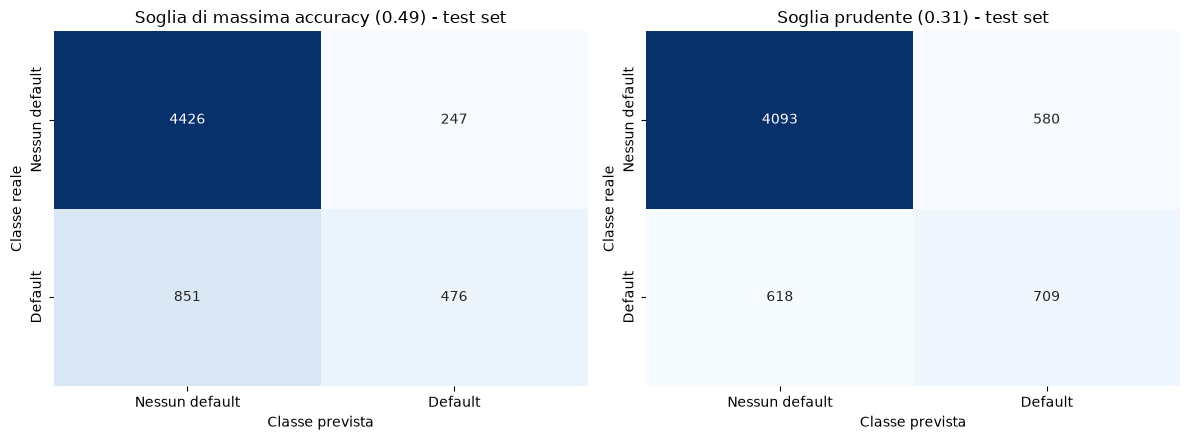

In [63]:
classNames = ["Nessun default", "Default"]
figure, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for axis, rowName in zip(axes, ["Soglia di massima accuracy", "Soglia prudente"]):
    prediction = (finalTestProbability >= finalThresholds[rowName]).astype(int)
    confusion = pd.crosstab(testY, prediction, rownames=["Classe reale"], colnames=["Classe prevista"])
    sns.heatmap(confusion, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axis,
                xticklabels=classNames, yticklabels=classNames)
    axis.set_title(f"{rowName} ({finalThresholds[rowName]:.2f}) - test set")
plt.tight_layout()
plt.show()

Nelle matrici le righe sono le classi reali e le colonne quelle previste. Sul test la soglia prudente individua poco più della metà dei default (recall 0,5343 contro 0,3587): i falsi negativi scendono da 851 a 618, i falsi positivi salgono da 247 a 580. L'accuracy passa da 0,8170 a 0,8003, sopra la baseline (0,7788); con precision 0,5500 più di metà dei clienti segnalati va davvero in default.

### Fasce di rischio

Se le probabilità sono affidabili, fra i clienti con rischio stimato intorno a un valore la frequenza di default osservata deve essere vicina a quel valore. I clienti del test set vengono divisi in cinque fasce di probabilità stimata.

,Clienti,Rischio medio previsto,Frequenza osservata
0-10%,1617,0.0680,0.0643
10-20%,2274,0.1445,0.1495
20-30%,773,0.2399,0.2070
30-50%,633,0.3825,0.4028
50-100%,703,0.6543,0.6657


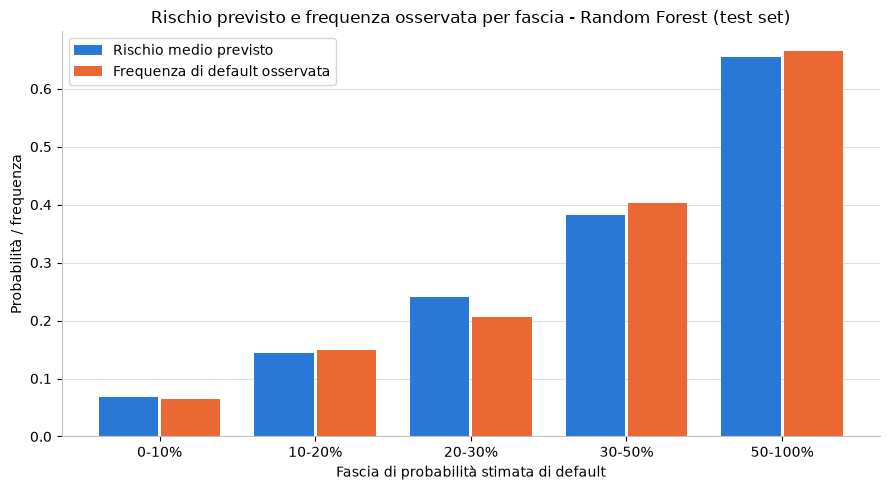

In [64]:
riskBandEdges = [0.10, 0.20, 0.30, 0.50]      # fasce fissate a priori, con estremi tondi
riskBandLabels = ["0-10%", "10-20%", "20-30%", "30-50%", "50-100%"]
# Indice della fascia di ogni cliente: 0 = 0-10%, ..., 4 = 50-100%
riskBand = np.digitize(finalTestProbability, riskBandEdges)

bandRows = {}
for bandIndex, bandLabel in enumerate(riskBandLabels):
    inBand = riskBand == bandIndex
    bandRows[bandLabel] = {"Clienti": inBand.sum(),
                           "Rischio medio previsto": finalTestProbability[inBand].mean(),
                           "Frequenza osservata": testY[inBand].mean()}
riskBands = pd.DataFrame.from_dict(bandRows, orient="index")
display(riskBands.round(4))

positions = np.arange(len(riskBandLabels))
plt.figure(figsize=(9, 5))
plt.bar(positions - 0.2, riskBands["Rischio medio previsto"], width=0.38, label="Rischio medio previsto")
plt.bar(positions + 0.2, riskBands["Frequenza osservata"], width=0.38, label="Frequenza di default osservata")
plt.xticks(positions, riskBandLabels)
plt.title("Rischio previsto e frequenza osservata per fascia - " + selectedModelName + " (test set)")
plt.xlabel("Fascia di probabilità stimata di default")
plt.ylabel("Probabilità / frequenza")
plt.grid(True, axis="y")
plt.legend()
plt.tight_layout()
plt.show()

La frequenza osservata cresce con la fascia, da 0,0643 a 0,6657, e resta vicina al rischio medio previsto; lo scarto più grande è nella fascia 20-30% (0,2399 previsto, 0,2070 osservato). Le probabilità della Random Forest si possono quindi leggere come rischi, non solo come punteggi per ordinare i clienti.

## 9. Conclusioni

### Risultati

- Tutti e cinque i modelli battono la baseline su validation e test, in loss e in accuracy; fra i quattro modelli non lineari le differenze sono di pochi millesimi, la regressione logistica è leggermente indietro.
- Il modello finale, scelto sul validation set, è la Random Forest con 20 clienti minimi per foglia: sul test cross-entropy 0,4321 contro 0,5284 della baseline, ROC-AUC 0,7738.
- Alla soglia di massima accuracy (0,49) l'accuracy sul test è 0,8170 contro 0,7788, ma il recall è 0,3587.
- Alla soglia prudente (0,31) il recall sul test sale a 0,5343 e i falsi negativi scendono da 851 a 618; la precision è 0,5500 e l'accuracy 0,8003.
- Le probabilità stimate sono vicine alle frequenze osservate in ogni fascia di rischio.
- L'informazione utile sta soprattutto nei ritardi di pagamento recenti, `DELAY_0` in particolare.

### Limiti

- **Campione e periodo**: una sola banca di Taiwan e un solo periodo (2005), con un mese di orizzonte; in un altro portafoglio o in un altro ciclo economico le probabilità andrebbero ristimate.
- **Validazione**: un solo split casuale, senza validazione incrociata; le scelte fatte sul validation set dipendono in parte da quei 6000 clienti.
- **Iperparametri**: griglie piccole (tre reti, quattro dimensioni delle foglie, tre numeri di foglie per il Gradient Boosting).
- **Costi degli errori**: i costi reali di falsi positivi e falsi negativi non sono noti; la soglia prudente è una regola di progetto, non il risultato di un calcolo dei costi.
- **Margine sulla baseline**: le feature spiegano solo una parte del comportamento dei clienti, quindi il vantaggio sulla baseline è contenuto e anche alla soglia prudente una parte dei default resta non individuata.

### Nota sul metodo: l'uso del test set

In questo notebook tutti e cinque i modelli sono stati valutati anche sul test set **a scopo di studio**, per confrontarne il comportamento su training, validation e test. In un'applicazione reale la procedura sarebbe stata diversa: confronto sul validation set, scelta del modello con la validation loss più bassa (qui la Random Forest, con la soglia prudente 0,31) e una sola valutazione sul test set, limitata a quel modello. La stima delle prestazioni è quindi quella della Random Forest (accuracy 0,8003, recall 0,5343, 618 falsi negativi sul test); i risultati degli altri quattro modelli servono solo al confronto.

Sul test il Gradient Boosting fa leggermente meglio in loss (0,4309 contro 0,4321), in ROC-AUC (0,7780 contro 0,7738) e, alla soglia prudente, in accuracy (0,8013 contro 0,8003, ma con 653 falsi negativi contro 618). Sceglierlo ora vorrebbe dire usare il test per una decisione e renderebbe ottimistica la stima delle prestazioni. Differenze di pochi millesimi rientrano nella variabilità del campione: sul validation set era davanti la Random Forest, sia in loss (il criterio di scelta) sia in ROC-AUC.